In [150]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

import matplotlib as plt

In [176]:
data = pd.read_csv('../data/blooms_taxonomy_dataset.csv')

# cleaning
data["Questions"] = data["Questions"].str.lower().str.replace(r'[^\w\s]', '', regex=True)

X = data["Questions"]
y = data["Category"]

UnicodeDecodeError: 'utf-8' codec can't decode byte 0x9f in position 40888: invalid start byte

In [161]:
#labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(np.unique(y_encoded))

print(f"Detected {num_classes} classes: {label_encoder.classes_}")

Detected 6 classes: ['BT1' 'BT2' 'BT3' 'BT4' 'BT5' 'BT6']


In [162]:
#data split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)


In [163]:
#vectorization
max_features = 1000 
vectorizer = TfidfVectorizer(stop_words='english', max_features=max_features, ngram_range=(1,2))

X_train_tfidf = vectorizer.fit_transform(X_train).toarray()
X_test_tfidf = vectorizer.transform(X_test).toarray()

print(f"Shape of training data: {X_train_tfidf.shape}")

Shape of training data: (8380, 1000)


In [164]:
#NN
model = Sequential([
    Dense(64, activation='relu', kernel_regularizer=l2(0.001), input_shape=(X_train_tfidf.shape[1],)),
    Dropout(0.5),
    
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    
    Dense(num_classes, activation='softmax')
])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [165]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [166]:
#train
history = model.fit(
    X_train_tfidf, y_train,
    epochs=20,         
    batch_size=32,
    validation_data=(X_test_tfidf, y_test),
    verbose=1
)

Epoch 1/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 891us/step - accuracy: 0.3178 - loss: 1.7047 - val_accuracy: 0.5940 - val_loss: 1.4305
Epoch 2/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 768us/step - accuracy: 0.5810 - loss: 1.3090 - val_accuracy: 0.7199 - val_loss: 1.0834
Epoch 3/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step - accuracy: 0.6800 - loss: 1.1080 - val_accuracy: 0.7281 - val_loss: 0.9870
Epoch 4/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - accuracy: 0.7167 - loss: 1.0336 - val_accuracy: 0.7414 - val_loss: 0.9528
Epoch 5/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 667us/step - accuracy: 0.7428 - loss: 0.9811 - val_accuracy: 0.7443 - val_loss: 0.9369
Epoch 6/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 660us/step - accuracy: 0.7481 - loss: 0.9608 - val_accuracy: 0.7452 - val_loss: 0.9225
Epoch 7/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 671us/step - accuracy: 0.7556 - loss: 0.9423 - val_accuracy: 0.7538 - val_loss: 0.9152
Epoch 8/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 694us/step - accuracy: 0.7704 - loss: 0.9161 - 

In [167]:
loss, accuracy = model.evaluate(X_test_tfidf, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step - accuracy: 0.7638 - loss: 0.8813
Test Accuracy: 76.38%


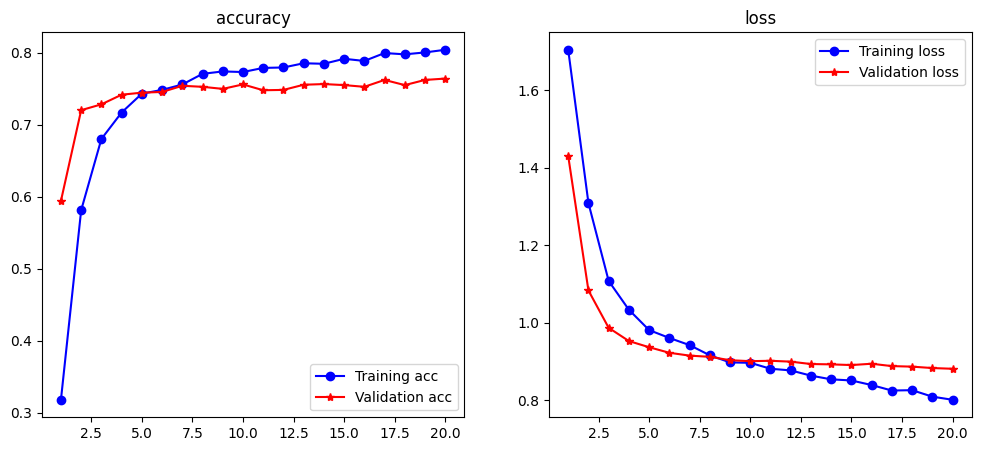

In [168]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title('accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title('loss')
    plt.legend()

    plt.show()

plot_history(history)

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step


<Figure size 1000x800 with 0 Axes>

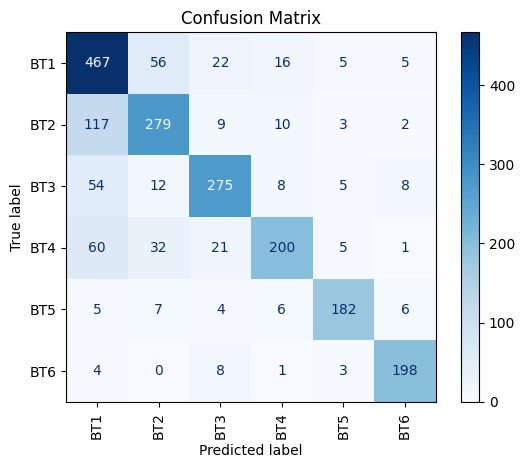

In [175]:
y_pred_probs = model.predict(X_test_tfidf)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Confusion Matrix")
plt.show()


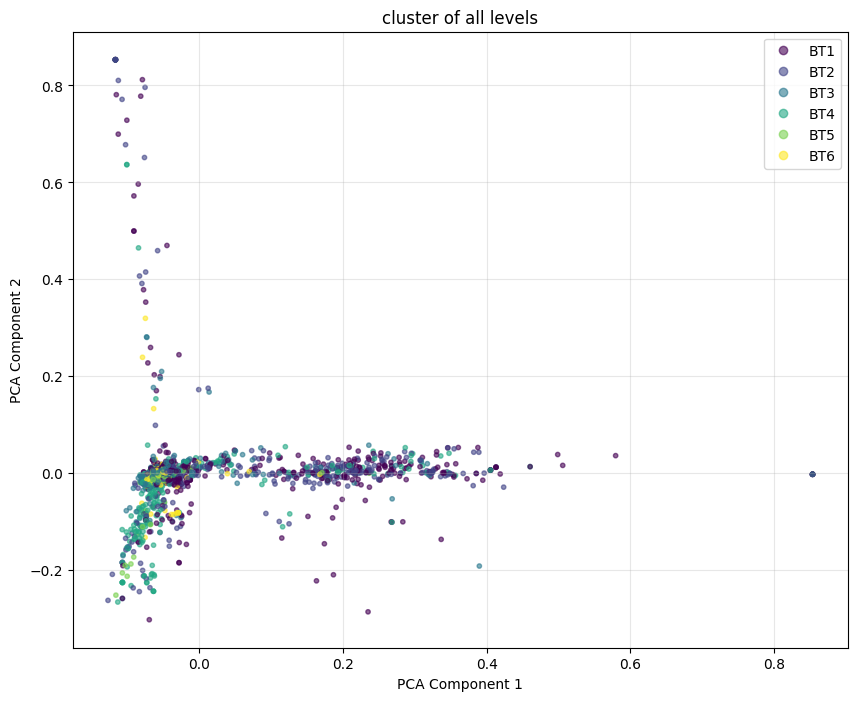

In [170]:
def plot_data_clusters(X_data, y_data, labels):
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_data)
    
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_data, cmap='viridis', alpha=0.6, s=10)
    
    plt.legend(handles=scatter.legend_elements()[0], labels=labels)
    plt.title('cluster of all levels')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.grid(True, alpha=0.3)
    plt.show()

class_names = list(label_encoder.classes_)
plot_data_clusters(X_test_tfidf, y_test, class_names)


In [171]:
#interface
def predict_bloom_level(new_question):
    clean_q = new_question.lower().replace(r'[^\w\s]', '')
    
    vec_q = vectorizer.transform([clean_q]).toarray()
    
    prediction_probs = model.predict(vec_q, verbose=0)
    predicted_index = np.argmax(prediction_probs)
    
    predicted_label = label_encoder.inverse_transform([predicted_index])[0]
    
    return predicted_label

In [177]:
test_q = "What conclusions can you draw by combining viewpoints from different political philosophers?"
print(f"Question: {test_q}")
print(f"Predicted Level: {predict_bloom_level(test_q)}")

test_q_2 = "Can you BT6 a flowchart diagram for a troubleshooting process?"
print(f"Question: {test_q_2}")
print(f"Predicted Level: {predict_bloom_level(test_q_2)}")

Question: What conclusions can you draw by combining viewpoints from different political philosophers?
Predicted Level: BT6
Question: Can you BT6 a flowchart diagram for a troubleshooting process?
Predicted Level: BT4
